# Sizing of Amplifier & Filter

**Copyright 2026 Simon Dorrer and Harald Pretl**

SPDX-License-Identifier: Apache-2.0 WITH SHL-2.1

**Version 2** of `sizing_filter.ipynb`. Changes against the original:

- Power budget over all corners: every corner (mos, res, -40 to 100 °C) must stay below `Ptot`.
- Reference resistor rppd instead of rhigh: rhigh drops 16 % from 27 to 100 °C, rppd rises 1.3 %.
- Current mirrors (M6/M7, M12/M14) sized at the drain voltages they really see, with equal finger widths.
- Output common mode set to VDD/2 through V_SG of M8/M9.
- First-stage loads M12/M13 and M14/M15 at L = 1 µm (input-referred offset roughly halved).
- Offset estimate (Pelgrom coefficients of the model), compensation from a phase margin target.
- All device sizes are exported to `otaSizing.spice`, used by `amp_no_enable_param.sch`.
- Removed: leftovers of the inverter template, the broken input and output stage cells.

## Imports, Constants and Filepaths

In [1]:
# Imports
import math
from spice_params import read_spice_params, write_spice_params
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from pygmid import Lookup as lk
# Constants
k_b = 1.380649e-23 #J/K
gamma = 2/3
T = 130+273.15 # worst case die temperature in Kelvin
# Filepaths
PASSIVES_SIZING ='filterPassivesSizing.spice'
OTA_SIZING = 'otaSizing.spice'

## Functions for plotting

In [2]:
# Round contour levels (steps of 1, 2 or 5 times a power of ten) over the range of z
def nice_levels(z, n=15):
    return MaxNLocator(n, steps=[1, 2, 5, 10]).tick_values(np.nanmin(z), np.nanmax(z))


# Frequency with unit prefix, for contour labels
def fmt_hz(f):
    for div, unit in ((1e9, 'GHz'), (1e6, 'MHz'), (1e3, 'kHz')):
        if f >= div:
            return f'{f/div:g} {unit}'
    return f'{f:g} Hz'

# Specifications

In [3]:
### SYSTEM LEVEL ###

# Start frequency [Hz]
fstart = 100

# Pass-band frequency (-3dB) [Hz]
fpass = 1e6

# Stop-band frequency (fs-fpass) [Hz]
fstop = 9e6

B = fstop - fstart
# Pass-band gain [dB]
Apass = 20

# Pass-band ripple [dB] (allowed)
Rpass = 0.1

# Stop-band attenuation [dB]
astop =49.9

# Maximum Filter order
maxord = 4

# Input/Output structure type
iostruct = "fully differential"

# Maximum number of amplifiers
maxamps = 2

# Max. SNDR (limited by ADC) [dB]
SNDRmax = 48.6

# Noise gain
beta = 1 / (1+10**(Apass/20))

In [4]:
### CHIP LEVEL ###

# Supply voltage
VDD = 1.5

# Input common-mode voltage
Vcm_in = VDD / 2

# Output common-mode voltage
Vcm_out = VDD / 2

# Maximum output signal [V]
Vfs = 1

# Load resistance [Ω]
Rl = 560e3

# Load capacitance [F]
Cl = 5e-12

# Maximum integrated output-referred noise 100Hz to fstop [V]
onoise = 113e-6

# OTA unity-gain bandwidth [Hz]
fug = 10e6 # naive approach
fug = 30*1*fpass/beta # approach of (10 to 100 -> 30)*Q(1)*fn(fpass)/beta0(1/11)

# Gain error [%]
epsilong = 1e6 # still to be determined

# Maximum chip area [μm²]
area = 200*200

# Maximum total power [W]
Ptot = 100e-6

# Maximum filter THD @ Vfs [dBc]
THDfilt = -60

# Number of bits of the ADC [bits]
nadc = 8

# Passband frequency [Hz]
fpass = 1e6

# Stopband frequency for use with digital decimator [Hz]
fstop_decimator = 9e6

# Stopband frequency [Hz]
fstop = 5e6

In [5]:
# Print Specifications
print("=" * 60)
print("Specifications:")
print("=" * 60)
print(f"Maximum output signal (Vfs) differential: {Vfs} V")
print(f"Load impedance:                           {Rl*1e-3} kΩ || {Cl*1e12} pF")
print(f"Integrated output-referred noise :       ≤{onoise*1e6} μV")
print(f"OTA unity-gain bandwidth fug:            >{fug*1e-6} MHz")
print(f"Gain error εg:                            {epsilong} %")
print(f"Supply voltage VDD:                       {VDD} V")
print(f"Maximum chip area:                       <{area} μm²")
print(f"Total power:                             <{Ptot*1e6} μW")
print(f"Filter THD @ Vfs:                        ≤{THDfilt} dBc")
print(f"Number of bits:                           {nadc}")
print(f"Passband frequency:                       {fpass*1e-6} MHz")
print(f"Stopband frequency w/ dig. decimator:     {fstop_decimator*1e-6} MHz")
print(f"Stopband frequency w/o dig. decimator:    {fstop*1e-6} MHz")
print("=" * 60)

Specifications:
Maximum output signal (Vfs) differential: 1 V
Load impedance:                           560.0 kΩ || 5.0 pF
Integrated output-referred noise :       ≤113.0 μV
OTA unity-gain bandwidth fug:            >330.0 MHz
Gain error εg:                            1000000.0 %
Supply voltage VDD:                       1.5 V
Maximum chip area:                       <40000 μm²
Total power:                             <100.0 μW
Filter THD @ Vfs:                        ≤-60 dBc
Number of bits:                           8
Passband frequency:                       1.0 MHz
Stopband frequency w/ dig. decimator:     9.0 MHz
Stopband frequency w/o dig. decimator:    5.0 MHz


In [6]:
# Peak SQNR w/ FS sine [dB]
sqnr_peak = 6.02 * nadc + 1.76
# LSB Volage for n bits[V]
Vlsb = Vfs/2**nadc
# Quantization noise for uniform distribution
Vqn = Vlsb/math.sqrt(12)
# Output Swing in RMS
Vorms = Vfs/(2*math.sqrt(2))
# Peak SNR for given noise and output power
SNRpeak = 10*math.log10(Vorms**2/(Vqn**2+onoise**2))

A0_dB = 20*math.log10(fug/fpass)
A0 = 10**(A0_dB/20)
#A0 = gm*R0
#In^2 = 2*4*k_b*T*gamma*gm*B
#In^2 = 2*4*k_b*T*gamma*B*A0/Ro
#Von^2=Ro^2*In^2=2*4*k_b*T*gamma*B*A0*Ro
#Von = Ro*In
#In^2*R0^2=In^2*A0^2/gm^2=8*k_b*T*gamma*B*gm*A0^2/gm^2
#=8*k_b*T*gamma*B*A^2/gm
# fehler in rechnung fixen, letzte rechnung stimmt aber herleitungen passen so nicht
# Stage-1 load M12/M13 adds its channel noise: factor (1 + gm_load/gm_DP),
# i.e. 1 + (gm/Id)_load/(gm/Id)_DP at equal currents; keep consistent with gm_id_DP_Load/gm_id_DP below
gm_id_ratio_load = 1
gm_min = (1 + gm_id_ratio_load) * 8*k_b*T*gamma*B*(1/beta)**2 / onoise**2
#gm_min = onoise **2 / (2*4*k_b*gamma*(273.15+130)*(fstop-fstart))
Ro_min = A0/gm_min
Cpole = gm_min/(2*math.pi*fug)

In [7]:
# Print Specifications
print("=" * 60)
print("Noise:")
print("=" * 60)
print(f"SQNR_peak:                  {sqnr_peak:.3f} dB")
print(f"Vlsb:                       {Vlsb*1e3:.3f} mV")
print(f"Quantisation noise Voltage: {Vqn*1e3:.3f} mVrms")
print(f"Output voltage:             {Vorms*1e3:.3f} mVrms")
print(f"SNR_peak:                   {SNRpeak:.3f} dB")
print(f"DC-Gain required:           {A0_dB:.3f} dB")
print(f"Required gm:                {gm_min*1e3:.3f} mS")
print(f"Required Ro:                {Ro_min*1e-3:.3f} kOhm")
print(f"Co for pole at fug:         {Cpole*1e12:.3f} pF")
print("=" * 60)

Noise:
SQNR_peak:                  49.920 dB
Vlsb:                       3.906 mV
Quantisation noise Voltage: 1.128 mVrms
Output voltage:             353.553 mVrms
SNR_peak:                   49.882 dB
DC-Gain required:           50.370 dB
Required gm:                5.063 mS
Required Ro:                65.173 kOhm
Co for pole at fug:         2.442 pF


# Load SG13CMOS5L Data Tables

In [8]:
lv_nmos = lk('data/sg13cmos5l_lv_nmos.mat')
lv_pmos = lk('data/sg13cmos5l_lv_pmos.mat')
# list of parameters: VGS, VDS, VSB, L, W, NFING, ID, VT, GM, GMB, GDS, CGG, CGB, CGD, CGS, CDD, CSS, STH, SFL
# if not specified, minimum L, VDS=max(vgs)/2=0.9 and VSB=0 are used 

# Filter Components Sizing

In [9]:
C_per_area = 1.287e-15 # pF/μm² für cmomf
# C = C_per_area * W*L
R_square = 1.645e3 # kΩ/quare für rhigh
# R = R_square * L/W

In [10]:
passives = read_spice_params("filterPassives.spice")
R1 = passives.get("R1")
R2 = passives.get("R2")
R3 = passives.get("R3")
R4 = passives.get("R4")

C1 = passives.get("C1")
C2 = passives.get("C2")
C3 = passives.get("C3")

W_R = 0.5 # 0.5μm
L_R1_exact = R1 / R_square * W_R
L_R2_exact = R2 / R_square * W_R
L_R3_exact = R3 / R_square * W_R
L_R4_exact = R4 / R_square * W_R

L_R1 = round(L_R1_exact / 0.5)*0.5
L_R2 = round(L_R2_exact / 0.5)*0.5
L_R3 = round(L_R3_exact / 0.5)*0.5
L_R4 = round(L_R4_exact / 0.5)*0.5

d_R1 = (L_R1_exact - L_R1) / W_R * R_square
d_R2 = (L_R2_exact - L_R2) / W_R * R_square
d_R3 = (L_R3_exact - L_R3) / W_R * R_square
d_R4 = (L_R4_exact - L_R4) / W_R * R_square

e_R1 = d_R1 / R1 * 100
e_R2 = d_R2 / R2 * 100
e_R3 = d_R3 / R3 * 100
e_R4 = d_R4 / R4 * 100

C_1_Area = C1 / C_per_area
C_2_Area = C2 / C_per_area
C_3_Area = C3 / C_per_area

L_C1_exact = math.sqrt(C_1_Area)
L_C2_exact = math.sqrt(C_2_Area)
L_C3_exact = math.sqrt(C_3_Area)

L_C1 = round(L_C1_exact/0.5)*0.5
L_C2 = round(L_C2_exact/0.5)*0.5
L_C3 = round(L_C3_exact/0.5)*0.5

d_C1 = C1 - C_per_area * L_C1**2
d_C2 = C2 - C_per_area * L_C2**2
d_C3 = C3 - C_per_area * L_C3**2

e_C1 = d_C1 / C1 * 100
e_C2 = d_C2 / C2 * 100
e_C3 = d_C3 / C3 * 100


In [11]:
# Passives area estimation
A_Res_Filter = W_R * (L_R1 + L_R2 + L_R3 + L_R4)
A_Cap_Filter = L_C1**2 + L_C2**2 + L_C3**2
A_Passives_Filter = A_Res_Filter + A_Cap_Filter
L_Passives_equiv = math.sqrt(A_Passives_Filter)

In [12]:
print("=" * 60)
print("Filter Passives Sizing:")
print("=" * 60)
print(f"W R:  {W_R}  μm")
print(f"L R1: {L_R1_exact:.3f} μm, rounded: {L_R1} μm")
print(f"L R2: {L_R2_exact:.3f} μm, rounded: {L_R2} μm")
print(f"L R3: {L_R3_exact:.3f} μm, rounded: {L_R3} μm")
print(f"L R4: {L_R4_exact:.3f} μm, rounded: {L_R4} μm")
print(f"L C1: {L_C1_exact:.3f} μm, rounded: {L_C1} μm")
print(f"L C2: {L_C2_exact:.3f} μm, rounded: {L_C2} μm")
print(f"L C3: {L_C3_exact:.3f} μm, rounded: {L_C3} μm")
print("=" * 60)
print("Deviation from exact target:")
print("=" * 60)
print(f"ΔR1: {d_R1:.3f} Ω, relative: {e_R1:.3f} %")
print(f"ΔR2: {d_R2:.3f} Ω, relative: {e_R2:.3f} %")
print(f"ΔR3: {d_R3:.3f} Ω, relative: {e_R3:.3f} %")
print(f"ΔR4: {d_R4:.3f} Ω, relative: {e_R4:.3f} %")
print(f"ΔC1: {d_C1*1e15:.3f} fF, relative: {e_C1:.3f} %")
print(f"ΔC2: {d_C2*1e15:.3f} fF, relative: {e_C2:.3f} %")
print(f"ΔC3: {d_C3*1e15:.3f} fF, relative: {e_C3:.3f} %")
print("=" * 60)
print("Minimum Passives Area (unreachable - 100% fill)")
print("=" * 60)
print(f"Resistor Area: {A_Res_Filter} μm²")
print(f"Capacitor Area: {A_Cap_Filter} μm²")
print(f"Filter passives Area: {A_Passives_Filter} μm²")
print(f"Filter passives side-lengt (assumes a square): {L_Passives_equiv:.3f} μm")
print("=" * 60)

Filter Passives Sizing:
W R:  0.5  μm
L R1: 3.162 μm, rounded: 3.0 μm
L R2: 31.618 μm, rounded: 31.5 μm
L R3: 5.921 μm, rounded: 6.0 μm
L R4: 48.375 μm, rounded: 48.5 μm
L C1: 139.374 μm, rounded: 139.5 μm
L C2: 19.710 μm, rounded: 19.5 μm
L C3: 27.875 μm, rounded: 28.0 μm
Deviation from exact target:
ΔR1: 532.200 Ω, relative: 5.116 %
ΔR2: 387.100 Ω, relative: 0.372 %
ΔR3: -259.300 Ω, relative: -1.331 %
ΔR4: -410.100 Ω, relative: -0.258 %
ΔC1: -45.342 fF, relative: -0.181 %
ΔC2: 10.618 fF, relative: 2.124 %
ΔC3: -9.008 fF, relative: -0.901 %
Minimum Passives Area (unreachable - 100% fill)
Resistor Area: 44.5 μm²
Capacitor Area: 20624.5 μm²
Filter passives Area: 20669.0 μm²
Filter passives side-lengt (assumes a square): 143.767 μm


## Write sizing to spice param file

In [13]:
passives_sizing = {'W_R': W_R, 'L_R1': L_R1, 'L_R2': L_R2, 'L_R3': L_R3, 'L_R4': L_R4, 'L_C1': L_C1, 'L_C2': L_C2, 'L_C3': L_C3}
write_spice_params(passives_sizing, PASSIVES_SIZING, microns=True)

Wrote 8 parameters to filterPassivesSizing.spice


## Noise Budget

In [14]:
# Output-referred noise of the complete filter with an ideal OTA, per half circuit:
# MFB biquad (R1, R2, R3, C1, C2) followed by the passive RC section (R4, C3).
# C1 and C3 are per-half values. A differential capacitor Cd between the two halves
# acts as 2*Cd per half, so it has to be built as Cd = C/2.
trapz = getattr(np, 'trapezoid', None) or np.trapz
f_noise = np.logspace(np.log10(fstart), np.log10(fstart + B), 4001)
s_noise = 2j * np.pi * f_noise

Y_X = 1/R1 + 1/R2 + 1/R3 + s_noise*C1      # admittance sum at the inner node of the MFB
D_noise = 1/R2 + Y_X*R3*s_noise*C2
H_RC = 1 / (1 + s_noise*R4*C3)

# Transfer functions from each resistor's noise voltage to the filter output
tf_noise = {
    'R1': -(1/R1) / D_noise * H_RC,          # same as the signal path
    'R2': -(1/R2) / D_noise * H_RC,
    'R3': -(Y_X - 1/R3) / D_noise * H_RC,
    'R4': H_RC,
}
R_noise = {'R1': R1, 'R2': R2, 'R3': R3, 'R4': R4}
# Noise gain from the OTA input to the filter output (11 at DC, peaks near fpass)
ng_ota = (Y_X*R3*s_noise*C2 + Y_X - 1/R3) / D_noise * H_RC

# Differential output noise power; the two halves add up for the resistors
vn2_res = {k: 2 * trapz(4*k_b*T*R_noise[k]*np.abs(h)**2, f_noise) for k, h in tf_noise.items()}
vn2_res_tot = sum(vn2_res.values())
vn2_left = onoise**2 - vn2_res_tot
int_ng2 = trapz(np.abs(ng_ota)**2, f_noise)

# gm of the input pair if the OTA may use this share of the noise power budget
ota_noise_share = 0.5
gm_noise = 8*k_b*T*gamma*(1 + gm_id_ratio_load)*int_ng2 / (ota_noise_share*onoise**2)

In [15]:
print("=" * 60)
print(f"Noise Budget (ideal OTA, {fstart:.0f} Hz to {(fstart + B)*1e-6:.1f} MHz, {T:.0f} K):")
print("=" * 60)
print(f"Check, signal gain at fstart: {np.abs(tf_noise['R1'][0]):.2f} (expected {10**(Apass/20):.2f})")
for k, v in vn2_res.items():
    print(f"Resistor {k}:                  {np.sqrt(v)*1e6:.1f} μV")
print(f"All resistors:                {np.sqrt(vn2_res_tot)*1e6:.1f} μV")
print(f"Budget:                       {onoise*1e6:.1f} μV")
if vn2_left <= 0:
    print("Note! Resistor noise alone exceeds the noise budget!")
else:
    print(f"Left for the OTA:             {np.sqrt(vn2_left)*1e6:.1f} μV")
print("-" * 60)
print(f"Integrated noise gain^2:      {int_ng2:.3g} Hz, flat (1/beta)^2*B: {(1/beta)**2*B:.3g} Hz")
print(f"gm for {ota_noise_share*100:.0f} % of the budget:    {gm_noise*1e3:.3f} mS, flat estimate (gm_min): {gm_min*1e3:.3f} mS")
print("=" * 60)

Noise Budget (ideal OTA, 100 Hz to 9.0 MHz, 403 K):
Check, signal gain at fstart: 10.00 (expected 10.00)
Resistor R1:                  220.2 μV
Resistor R2:                  69.6 μV
Resistor R3:                  480.7 μV
Resistor R4:                  101.7 μV
All resistors:                542.9 μV
Budget:                       113.0 μV
Note! Resistor noise alone exceeds the noise budget!
------------------------------------------------------------
Integrated noise gain^2:      2.73e+08 Hz, flat (1/beta)^2*B: 1.09e+09 Hz
gm for 50 % of the budget:    2.543 mS, flat estimate (gm_min): 5.063 mS


## Power Budget

In [16]:
# Power budget over all corners.
# The OTA current depends on the corner: the reference current is (VDD - VSG)/R_ref.
# k_corner = I_VDD(worst corner) / I_VDD(tt, 27 °C), including the current into the load Rl.
# Simulated for this topology and sizing with the rppd reference over
# mos tt/ss/ff/sf/fs x res typ/bcs/wcs x -40/27/100 °C (worst: ff, res_bcs).
# Re-check it after a larger change of the sizing.
k_corner = 1.243
i_tot_worst = Ptot / VDD
i_tot_targ = i_tot_worst / k_corner     # allowed supply current at tt, 27 °C
i_load = 2 * Vcm_out / Rl               # supplied by M8/M9 into the load resistors
# Main expenses: Output Stage + Input Stage
# Current reference paths ~ 1/10 of input stage
# Output stage ~ 2 * input stage
# Total: 1/10 + 1 + 2*2 = 5.1, kept at 5.2 as in the first version (margin for rounding)
i_unit = (i_tot_targ - i_load) / 5.2
id_diode_bias = 0.1 * i_unit
id_input_bias = i_unit                  # tail current, i.e. both sides of the input pair
id_output_mirror = 2 * i_unit           # each side of the output stage

print(f"Current Budget for {Ptot*1e6} μW Power Target over all corners")
print(f"I_total, worst corner: {i_tot_worst*1e6:.3f} μA")
print(f"I_total, tt 27 °C:     {i_tot_targ*1e6:.3f} μA  (k_corner = {k_corner}), of which {i_load*1e6:.3f} μA into Rl")
print(f"ID Bias Gen:   {id_diode_bias*1e6:.3f} μA")
print(f"ID Input Bias: {id_input_bias*1e6:.3f} μA (tail), {id_input_bias/2*1e6:.3f} μA per side")
print(f"ID Output Stage: {id_output_mirror*1e6:.3f} μA each")

Current Budget for 100.0 μW Power Target over all corners
I_total, worst corner: 66.667 μA
I_total, tt 27 °C:     53.634 μA  (k_corner = 1.243), of which 2.679 μA into Rl
ID Bias Gen:   0.980 μA
ID Input Bias: 9.799 μA (tail), 4.900 μA per side
ID Output Stage: 19.598 μA each


## Violation of Noise Budget guaranteed 
The resistors break the noise budget by more than the Amp was ever allowed to have.  
The resistors can only get smaller if the capacitances increase and they are already at half the area allowed for C1 alone.  
So: noise budget secondary and <b>power budget primary</b>.

# OTA Sizing

## Topology and Operating Point

- M6 (diode) and the rppd resistor R1 set the reference current, M7 mirrors it into the tail.
- M18/M19: PMOS input pair. M12/M13: first-stage loads; their gates sit at the midpoint of the
  resistor string xr1, so they act as diodes for the common mode and as current sources for the
  differential signal. The first-stage output common mode is therefore V_GS of M12/M13.
- M14/M15 share this gate voltage, so M12 → M14 is a current mirror. M14 sees V_DS = V_out,cm,
  M12 only V_GS: the mirror is sized with the current density at the real V_DS, not with the W ratio.
- M8/M9 are biased by the string xr2 the same way, so V_out,cm = VDD − V_SG(M8). M8/M9 are sized for
  V_SG = VDD/2 at their current, which sets the output common mode to VDD/2.
- Miller compensation C6/C7 = C_C from each output back to the opposite first-stage output.

In [17]:
# Design choices (free parameters)
gm_id_ref, L_ref = 7.5, 0.75           # M6 reference diode; M7 (tail) uses the same L
gm_id_dp, L_dp, NG_dp = 15, 0.5, 1     # M18/M19 input pair
gm_id_ld1, L_ld1 = 15, 1.0             # M12/M13 first-stage load; M14/M15 use the same L (mirror)
L_ld2, NG_ld2 = 0.5, 1                 # M8/M9 second-stage load, gm/ID follows from V_SG = VDD/2
R_str = 1e6                            # CM string resistance per side (rstring_cm: 2 x 1 MΩ)
W_rref = 0.5                           # [µm] width of the rppd reference resistor
PM_target = 60                         # [°] phase margin target for the compensation
C_L_ota = Cl                           # [F] capacitive load at the OTA output (spec load 5 pF,
                                       # in the filter the OTA sees less: 5 pF sits behind R4)
wf_min = 0.5                           # [µm] minimum finger width in the mirrors
# Pelgrom coefficients of the model (sg13g2_moslv_mismatch.lib): σ(ΔVth) per device = A_vt/sqrt(W·L)
A_vt_n, A_vt_p = 3.9e-3, 2.2e-3        # [V·µm]
A_b_n, A_b_p = 0.005, 0.0033           # [µm], relative current factor mismatch per device

In [18]:
# Helpers
def f(x):
    """ pygmid returns arrays, also for scalar lookups """
    return float(np.squeeze(x))


def vgs_diode(dev, gm_id, L):
    """ V_GS of a diode-connected device (V_DS = V_GS) at the given gm/ID """
    v = 0.5
    for _ in range(30):
        v = f(dev.lookupVGS(GM_ID=gm_id, L=L, VDS=v, VSB=0))
    return v


VGS_GRID = np.linspace(0.2, 1.2, 501)


def id_w(dev, L, vgs, vds):
    """ Current density at given VGS and VDS (scalar) """
    return f(dev.lookup('ID_W', VGS=vgs, VDS=vds, L=L))


def vgs_for_id_w(dev, L, target, vds=None):
    """ V_GS that gives the current density target; vds=None: diode (V_DS = V_GS) """
    j = np.array([id_w(dev, L, v, v if vds is None else vds) for v in VGS_GRID])
    return float(np.interp(target, j, VGS_GRID))


def mirror_fingers(W_a, W_b, ng_max=12, wf_step=0.01):
    """ Equal finger width for two mirror devices: returns ng_a, ng_b, finger width [µm]
        with the smallest error of W_b; the finger width is rounded to wf_step """
    best = None
    for ng_a in range(1, ng_max + 1):
        wf = round(W_a / ng_a / wf_step) * wf_step
        if wf < wf_min and ng_a > 1:
            break
        ng_b = max(1, round(W_b / wf))
        err = abs(ng_b * wf - W_b) / W_b + abs(ng_a * wf - W_a) / W_a
        if best is None or err < best[3]:
            best = (ng_a, ng_b, wf, err)
    return best[:3]

In [19]:
# Currents at tt, 27 °C
I_ref = id_diode_bias
I_tail = id_input_bias
I1 = I_tail / 2                 # per side of the input pair
I2 = id_output_mirror           # per side of the output stage
I8 = I2 + Vcm_out / Rl          # M8 also feeds the load resistor

# First-stage load M12/M13: diode for the common mode
VGS12 = vgs_diode(lv_nmos, gm_id_ld1, L_ld1)
W12_exact = I1 / f(lv_nmos.lookup('ID_W', GM_ID=gm_id_ld1, L=L_ld1, VDS=VGS12))

# Input pair M18/M19: source at viref1 = Vcm_in + VSG, drain at VGS12
VSD18 = 0.4
for _ in range(30):
    VSG18 = f(lv_pmos.lookupVGS(GM_ID=gm_id_dp, L=L_dp, VDS=VSD18, VSB=0))
    viref1 = Vcm_in + VSG18
    VSD18 = viref1 - VGS12
W18_exact = I1 / f(lv_pmos.lookup('ID_W', GM_ID=gm_id_dp, L=L_dp, VDS=VSD18))
W18 = round(W18_exact / NG_dp / 0.01) * 0.01 * NG_dp
VSD7 = VDD - viref1             # tail transistor M7

# Second stage M14/M15: gate at VGS12, drain at Vcm_out
W14_exact = I2 / id_w(lv_nmos, L_ld1, VGS12, Vcm_out)
NG12, NG14, wf_n = mirror_fingers(W12_exact, W14_exact)
W12, W14 = NG12 * wf_n, NG14 * wf_n
VGS12 = vgs_for_id_w(lv_nmos, L_ld1, I1 / W12)          # after rounding
I2 = W14 * id_w(lv_nmos, L_ld1, VGS12, Vcm_out)         # realised current
I8 = I2 + Vcm_out / Rl

# Second-stage load M8/M9: V_SG = VDD - Vcm_out
VSG8 = VDD - Vcm_out
W8 = round(I8 / id_w(lv_pmos, L_ld2, VSG8, VSG8) / NG_ld2 / 0.01) * 0.01 * NG_ld2
gm_id_8 = f(lv_pmos.lookup('GM_ID', VGS=VSG8, VDS=VSG8, L=L_ld2))

# Reference M6 and tail M7: equal finger width, ratio by the number of fingers
VSG6 = vgs_diode(lv_pmos, gm_id_ref, L_ref)
W6_exact = I_ref / f(lv_pmos.lookup('ID_W', GM_ID=gm_id_ref, L=L_ref, VDS=VSG6))
W7_exact = I_tail / id_w(lv_pmos, L_ref, VSG6, VSD7)
_, NG7, W6 = mirror_fingers(W6_exact, W7_exact, ng_max=1)
W7 = NG7 * W6
# VSG6 that gives exactly I_tail with the rounded sizes, and the reference current that belongs to it
VSG6 = vgs_for_id_w(lv_pmos, L_ref, I_tail / W7, vds=VSD7)
I_ref = W6 * id_w(lv_pmos, L_ref, VSG6, VSG6)

# Reference resistor (rppd, value formula of the PDK symbol at 27 °C, typ)
R_ref = (VDD - VSG6) / I_ref
W_R_ref = W_rref * 1e-6
L_rref = (R_ref - 70e-6 / W_R_ref) * (W_R_ref + 6e-9) / 260.0 * 1e6    # [µm]
L_rref = round(L_rref / 0.5) * 0.5

I_tot = I_ref + I_tail + 2 * I8
print("=" * 60)
print("Operating point (tt, 27 °C, lookup)")
print("=" * 60)
print(f"VSG M6:   {VSG6*1e3:.1f} mV    VSD M7:  {VSD7*1e3:.1f} mV")
print(f"VSG M18:  {VSG18*1e3:.1f} mV    VSD M18: {VSD18*1e3:.1f} mV   viref1: {viref1*1e3:.1f} mV")
print(f"VGS M12:  {VGS12*1e3:.1f} mV (first-stage output CM)")
print(f"VSG M8:   {VSG8*1e3:.1f} mV (output CM {Vcm_out*1e3:.0f} mV), gm/ID M8: {gm_id_8:.1f} S/A")
print(f"I_ref {I_ref*1e6:.3f} μA, I_tail {I_tail*1e6:.3f} μA, I2 {I2*1e6:.3f} μA, I_total {I_tot*1e6:.2f} μA"
      f" -> {I_tot*VDD*1e6:.1f} μW at tt, {I_tot*VDD*k_corner*1e6:.1f} μW worst corner (estimate)")
print(f"Mirror M12 -> M14: W ratio {W14/W12:.3f} for a current ratio of {I2/I1:.3f}")

Operating point (tt, 27 °C, lookup)
VSG M6:   597.7 mV    VSD M7:  301.8 mV
VSG M18:  448.2 mV    VSD M18: 874.0 mV   viref1: 1198.2 mV
VGS M12:  324.0 mV (first-stage output CM)
VSG M8:   750.0 mV (output CM 750 mV), gm/ID M8: 4.9 S/A
I_ref 0.934 μA, I_tail 9.799 μA, I2 19.499 μA, I_total 52.41 μA -> 78.6 μW at tt, 97.7 μW worst corner (estimate)
Mirror M12 -> M14: W ratio 3.250 for a current ratio of 3.980


In [20]:
# Small-signal values at the operating point
gm18 = gm_id_dp * I1
gds18 = gm18 / f(lv_pmos.lookup('GM_GDS', GM_ID=gm_id_dp, L=L_dp, VDS=VSD18))
gm_id_12 = f(lv_nmos.lookup('GM_ID', VGS=VGS12, VDS=VGS12, L=L_ld1))
gm12 = gm_id_12 * I1
gds12 = gm12 / f(lv_nmos.lookup('GM_GDS', VGS=VGS12, VDS=VGS12, L=L_ld1))
gm_id_14 = f(lv_nmos.lookup('GM_ID', VGS=VGS12, VDS=Vcm_out, L=L_ld1))
gm14 = gm_id_14 * I2
gds14 = gm14 / f(lv_nmos.lookup('GM_GDS', VGS=VGS12, VDS=Vcm_out, L=L_ld1))
gm8 = gm_id_8 * I8
gds8 = gm8 / f(lv_pmos.lookup('GM_GDS', VGS=VSG8, VDS=VSG8, L=L_ld2))

A1 = gm18 / (gds18 + gds12 + 1/R_str)
A2 = gm14 / (gds14 + gds8 + 1/R_str + 1/Rl)
A0_est = A1 * A2


# Input-referred offset (1 sigma): input pair plus first-stage loads, the second stage is
# divided by A1 and negligible (Monte Carlo of the first version: 0.11 mV of 5.1 mV)
def sigma_pair(A_vt, A_b, W, L, gm_id):
    s_vt = math.sqrt(2) * A_vt / math.sqrt(W * L)
    s_b = math.sqrt(2) * A_b / math.sqrt(W * L) / gm_id
    return math.hypot(s_vt, s_b)


s_os_dp = sigma_pair(A_vt_p, A_b_p, W18, L_dp, gm_id_dp)
s_os_ld = sigma_pair(A_vt_n, A_b_n, W12, L_ld1, gm_id_12) * gm12 / gm18
s_os = math.hypot(s_os_dp, s_os_ld)

print("=" * 60)
print("Gain and offset (estimate)")
print("=" * 60)
print(f"gm/ID: M18 {gm_id_dp:.1f}, M12 {gm_id_12:.1f}, M14 {gm_id_14:.1f}, M8 {gm_id_8:.1f} S/A")
print(f"A1: {20*np.log10(A1):.1f} dB, A2: {20*np.log10(A2):.1f} dB, A0: {20*np.log10(A0_est):.1f} dB"
      f" (spec {A0_dB:.1f} dB from fug/fpass)")
print(f"Offset σ: input pair {s_os_dp*1e3:.2f} mV, loads {s_os_ld*1e3:.2f} mV, total {s_os*1e3:.2f} mV")
print(f"Output offset in the filter (noise gain {1/beta:.0f}): σ {s_os/beta*1e3:.0f} mV differential")

Gain and offset (estimate)
gm/ID: M18 15.0, M12 15.0, M14 14.0, M8 4.9 S/A
A1: 24.4 dB, A2: 27.4 dB, A0: 51.7 dB (spec 50.4 dB from fug/fpass)
Offset σ: input pair 1.95 mV, loads 3.34 mV, total 3.86 mV
Output offset in the filter (noise gain 11): σ 42 mV differential


### Sweep: First-Stage Loads

The loads M12/M13 dominate the offset. Larger L or lower gm/ID reduce it; lower gm/ID also raises
V_GS, i.e. the first-stage output common mode and the gate voltage of M14/M15.
Currents fixed at the values above.

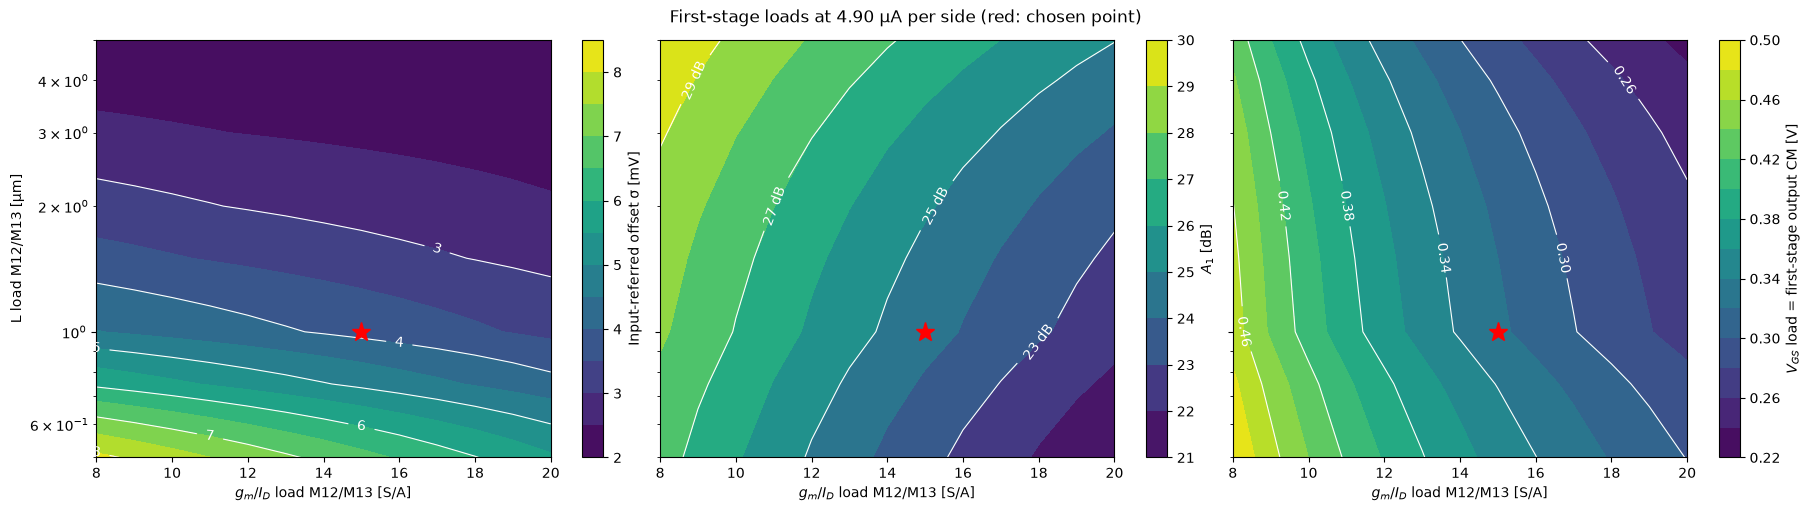

In [21]:
gm_id_ld_sw = np.linspace(8, 20, 13)
L_ld_sw = np.array([0.5, 0.75, 1, 1.5, 2, 3, 4, 5])
S_os = np.zeros((len(L_ld_sw), len(gm_id_ld_sw)))
A1_sw = np.zeros_like(S_os)
VGS_sw = np.zeros_like(S_os)
for i, Ls in enumerate(L_ld_sw):
    for j, g in enumerate(gm_id_ld_sw):
        v = vgs_diode(lv_nmos, g, Ls)
        Wl = I1 / f(lv_nmos.lookup('ID_W', GM_ID=g, L=Ls, VDS=v))
        gds_l = g * I1 / f(lv_nmos.lookup('GM_GDS', GM_ID=g, L=Ls, VDS=v))
        S_os[i, j] = math.hypot(s_os_dp, sigma_pair(A_vt_n, A_b_n, Wl, Ls, g) * g / gm_id_dp)
        A1_sw[i, j] = gm18 / (gds18 + gds_l + 1/R_str)
        VGS_sw[i, j] = v
X, Y = np.meshgrid(gm_id_ld_sw, L_ld_sw)

plots = [(S_os*1e3, 'Input-referred offset σ [mV]', '%g'),
         (20*np.log10(A1_sw), '$A_1$ [dB]', '%g dB'),
         (VGS_sw, '$V_{GS}$ load = first-stage output CM [V]', '%.2f')]
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True, constrained_layout=True)
for ax, (z, label, fmt) in zip(axs, plots):
    cf = ax.contourf(X, Y, z, levels=nice_levels(z), cmap='viridis')
    fig.colorbar(cf, ax=ax, label=label)
    cs = ax.contour(X, Y, z, levels=cf.levels[::2], colors='white', linewidths=0.8)
    ax.clabel(cs, fmt=fmt)
    ax.plot(gm_id_ld1, L_ld1, 'r*', ms=14)
    ax.set(xlabel='$g_m/I_D$ load M12/M13 [S/A]', yscale='log')
axs[0].set_ylabel('L load M12/M13 [µm]')
fig.suptitle(f'First-stage loads at {I1*1e6:.2f} µA per side (red: chosen point)')
plt.show()

## Compensation

Two-stage Miller OTA: GBW = gm18/(2π C_C), non-dominant pole p2 ≈ gm14/(2π C_L),
right-half-plane zero z = gm14/(2π C_C), i.e. z/GBW = gm14/gm18.
PM ≈ 90° − atan(GBW/p2) − atan(GBW/z). The estimate is conservative: the first version
(C_C = 1.221 pF) gave 37° here and 43° in the simulation.

In [22]:
p2 = gm14 / (2*np.pi*C_L_ota)
phi_z = np.degrees(np.arctan(gm18 / gm14))


def gbw_for_pm(pm):
    ang = 90 - pm - phi_z
    return p2 * np.tan(np.radians(ang)) if ang > 0 else float('nan')


GBW = gbw_for_pm(PM_target)
C_C = gm18 / (2*np.pi*GBW)
print(f"p2: {p2*1e-6:.2f} MHz, z/GBW: {gm14/gm18:.2f} (costs {phi_z:.1f}°)")
print(f"{'PM [°]':>7} {'GBW [MHz]':>10} {'C_C [pF]':>9} {'C_C area each [µm²]':>20}")
for pm in [40, 45, 50, 55, 60, 65]:
    g = gbw_for_pm(pm)
    c = gm18 / (2*np.pi*g)
    print(f"{pm:7d} {g*1e-6:10.2f} {c*1e12:9.3f} {c/C_per_area:20.0f}")
print(f"Chosen: PM {PM_target}°, GBW {GBW*1e-6:.2f} MHz (filter target fug {fug*1e-6:.0f} MHz), C_C {C_C*1e12:.3f} pF")
C_C = round(C_C * 1e15) * 1e-15

p2: 8.72 MHz, z/GBW: 3.73 (costs 15.0°)
 PM [°]  GBW [MHz]  C_C [pF]  C_C area each [µm²]
     40       6.10     1.918                 1490
     45       5.03     2.326                 1807
     50       4.06     2.880                 2238
     55       3.17     3.691                 2868
     60       2.33     5.015                 3896
     65       1.53     7.626                 5925
Chosen: PM 60°, GBW 2.33 MHz (filter target fug 330 MHz), C_C 5.015 pF


## Device Sizes and Export

In [23]:
devices = [  # name, devices, W [µm], L [µm], ng
    ('REF',  'M6',      W6,  L_ref, 1),
    ('TAIL', 'M7',      W7,  L_ref, NG7),
    ('DP',   'M18/M19', W18, L_dp,  NG_dp),
    ('LD1',  'M12/M13', W12, L_ld1, NG12),
    ('CS2',  'M14/M15', W14, L_ld1, NG14),
    ('LD2',  'M8/M9',   W8,  L_ld2, NG_ld2),
]
print(f"{'param':6} {'device':9} {'W [µm]':>8} {'L [µm]':>7} {'ng':>3} {'W/ng [µm]':>10}")
for name, dev_names, W, L, ng in devices:
    print(f"{name:6} {dev_names:9} {W:8.2f} {L:7.2f} {ng:3d} {W/ng:10.3f}")
print(f"RREF   R1 (rppd) W {W_rref} µm, L {L_rref} µm, {R_ref*1e-3:.1f} kΩ")
print(f"C_C    C6/C7     {C_C*1e12:.3f} pF")

ota_sizing = {}
for name, _, W, L, ng in devices:
    ota_sizing[f'W_{name}'] = W * 1e-6
    ota_sizing[f'L_{name}'] = L * 1e-6
    ota_sizing[f'NG_{name}'] = ng
ota_sizing['W_RREF'] = W_rref * 1e-6
ota_sizing['L_RREF'] = L_rref * 1e-6
ota_sizing['C_C'] = C_C
write_spice_params(ota_sizing, OTA_SIZING)

param  device      W [µm]  L [µm]  ng  W/ng [µm]
REF    M6            0.26    0.75   1      0.260
TAIL   M7            2.86    0.75  11      0.260
DP     M18/M19       5.16    0.50   1      5.160
LD1    M12/M13       2.76    1.00   4      0.690
CS2    M14/M15       8.97    1.00  13      0.690
LD2    M8/M9         1.74    0.50   1      1.740
RREF   R1 (rppd) W 0.5 µm, L 1879.5 µm, 966.0 kΩ
C_C    C6/C7     5.015 pF
Wrote 21 parameters to otaSizing.spice


In [24]:
# Area estimation (devices only, 100 % fill, no wiring)
A_mos = W6*L_ref + W7*L_ref + 2*(W18*L_dp + W12*L_ld1 + W14*L_ld1 + W8*L_ld2)
A_rref = W_rref * L_rref
A_cc = 2 * C_C / C_per_area
print("=" * 60)
print("OTA - Area Estimation (unreachable - 100% fill)")
print("=" * 60)
print(f"Transistors:      {A_mos:.1f} μm²")
print(f"Reference R1:     {A_rref:.1f} μm²")
print(f"C_C (2x, cmom):   {A_cc:.1f} μm²")
print(f"OTA total:        {A_mos + A_rref + A_cc:.1f} μm², with the filter passives: {A_mos + A_rref + A_cc + A_Passives_Filter:.0f} μm² of {area} μm²")

OTA - Area Estimation (unreachable - 100% fill)
Transistors:      32.7 μm²
Reference R1:     939.8 μm²
C_C (2x, cmom):   7793.3 μm²
OTA total:        8765.8 μm², with the filter passives: 29435 μm² of 40000 μm²
